In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/LZ46LTL6O2.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/13H1VTAZ42.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/G0DWU2GK1L.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/CVPHC0DT1P.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/90XJFQDL7G.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/3V8LZ56MOW.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/Y9EUV6TNP2.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/K76P42J0GK.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/ZSS7THB1UM.jpg
/kaggle/input/comp

In [2]:
import pandas as pd

df = pd.read_csv("/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv")

# Identify positive defect masks
has_mask = ( df["mask_rle"].notna()& df["mask_rle"].astype("string").str.strip().ne(""))

# Count positive samples for each defect class
positive_counts = df.loc[has_mask, "defect_type"].value_counts()
print("Positive samples by class:")
print(positive_counts)

# Count completely clean images
positive_images = df.loc[has_mask, "image_id"].nunique()
total_images = df["image_id"].nunique()
clean_images = total_images - positive_images

# Calculate the answer
answer = int(positive_counts.max()) + int(clean_images)

print("Completely clean images:", clean_images)
print("Final answer:", answer)

Positive samples by class:
defect_type
defect_c    4100
defect_d    1707
defect_a    1081
defect_b     313
Name: count, dtype: int64
Completely clean images: 5516
Final answer: 9616


# Question : 1:  RLE Standards — Column-Major Encoding on a 2D Grid
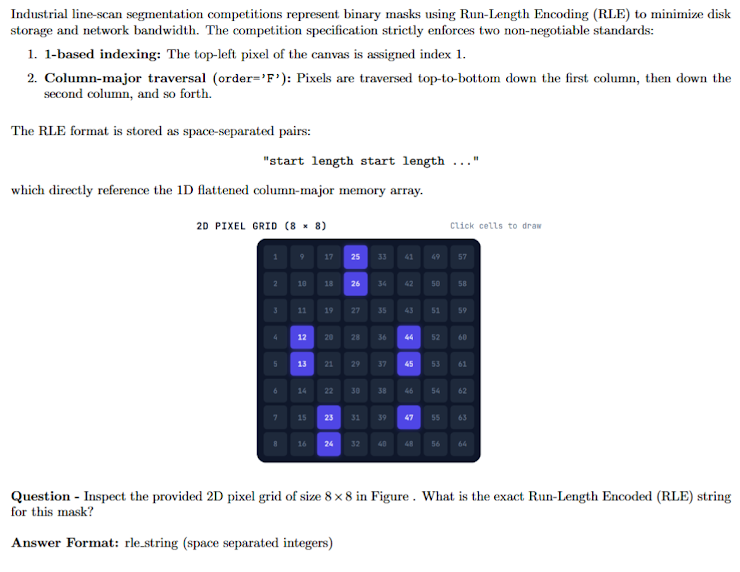

In [3]:
import numpy as np

def encode_rle(mask):
    pixels = mask.flatten(order="F").astype(np.uint8)

    padded = np.concatenate(([0], pixels, [0]))
    changes = np.where(padded[1:] != padded[:-1])[0]

    starts = changes[::2] + 1
    lengths = changes[1::2] - changes[::2]

    return " ".join(
        f"{start} {length}"
        for start, length in zip(starts, lengths)
    )

# Create the 8×8 binary mask
mask = np.zeros((8, 8), dtype=np.uint8)

# Highlighted pixel indices (1-based, column-major)
positions = [12, 13, 23, 24, 25, 26, 44, 45, 47]

for p in positions:
    row = (p - 1) % 8
    col = (p - 1) // 8
    mask[row, col] = 1

print("RLE:", encode_rle(mask))

RLE: 12 2 23 4 44 2 47 1


# Question : 2: RLE Decoding in Practice — Multi-Defect Pixel Mass

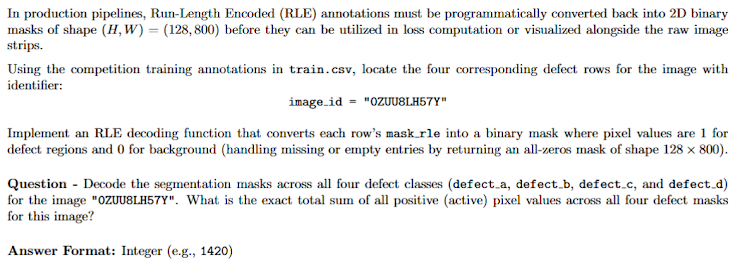

In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv("/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv")

HEIGHT, WIDTH = 128, 800
IMAGE_ID = "0ZUU8LH57Y"

CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]


def decode_rle(rle):
    mask = np.zeros(HEIGHT * WIDTH, dtype=np.uint8)

    if pd.isna(rle) or not str(rle).strip():
        return mask.reshape((HEIGHT, WIDTH), order="F")

    values = np.asarray(str(rle).split(), dtype=np.int64)

    if len(values) % 2:
        raise ValueError("Malformed RLE")

    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        end = start + length
        if start < 0 or length <= 0 or end > HEIGHT * WIDTH:
            raise ValueError("RLE index out of bounds")
        mask[start:end] = 1

    return mask.reshape((HEIGHT, WIDTH), order="F")


# Select the four annotation rows for this image
image_rows = df[df["image_id"].astype(str) == IMAGE_ID]

if image_rows.empty:
    raise ValueError(f"Image ID {IMAGE_ID} not found. Check the ID spelling.")

total_positive_pixels = 0

for defect in CLASSES:
    rows = image_rows[image_rows["defect_type"] == defect]

    if len(rows) != 1:
        raise ValueError(f"Expected one row for {defect}, found {len(rows)}")

    mask = decode_rle(rows.iloc[0]["mask_rle"])
    pixel_count = int(mask.sum())
    total_positive_pixels += pixel_count

    print(f"{defect}: {pixel_count} positive pixels")

print("\nFinal answer:", total_positive_pixels)

defect_a: 250 positive pixels
defect_b: 0 positive pixels
defect_c: 1232 positive pixels
defect_d: 5032 positive pixels

Final answer: 6514


# Question 3: Global Class Distribution and Defect Prevalence

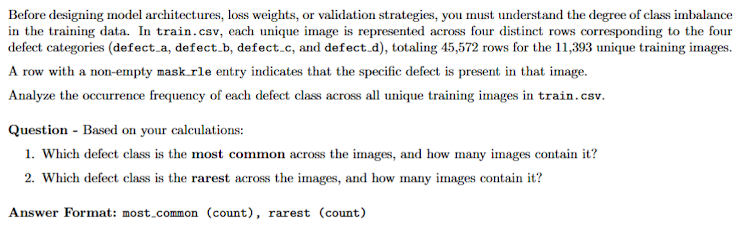

In [5]:
import pandas as pd
from pathlib import Path

CSV_PATH = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv")

df = pd.read_csv(CSV_PATH)

# A non-empty mask means the defect is present
has_mask = (df["mask_rle"].notna() & df["mask_rle"].astype("string").str.strip().ne(""))

# Count positive images for each defect class
counts = (
    df.loc[has_mask]
    .groupby("defect_type")["image_id"]
    .nunique()
    .sort_values(ascending=False)
)

most_common = counts.idxmax()
most_common_count = int(counts.max())

rarest = counts.idxmin()
rarest_count = int(counts.min())

print("Defect frequencies:")
print(counts.to_string())

print(f"\nAnswer: {most_common} ({most_common_count}), {rarest} ({rarest_count})")

Defect frequencies:
defect_type
defect_c    4100
defect_d    1707
defect_a    1081
defect_b     313

Answer: defect_c (4100), defect_b (313)


# Question 4: Multi-Label Defect Co-Occurrence Matrix

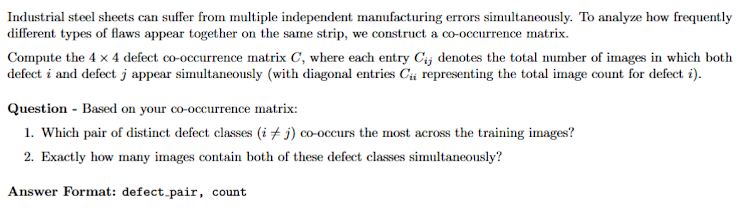!

In [6]:
import pandas as pd
from itertools import combinations
from pathlib import Path

CSV_PATH = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv")
df = pd.read_csv(CSV_PATH)
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]

# A defect is present if its RLE mask is non-empty
df["has_mask"] = (df["mask_rle"].notna()& df["mask_rle"].astype("string").str.strip().ne(""))

# One row per image, one Boolean column per defect class
presence = (
    df.pivot(index="image_id", columns="defect_type", values="has_mask")
    .reindex(columns=CLASSES)
    .fillna(False)
    .astype(bool)
)

# Co-occurrence matrix: number of images containing both classes
cooccurrence = presence.astype(int).T @ presence.astype(int)

print("Co-occurrence matrix:")
print(cooccurrence)

# Find the most frequent pair of distinct defect classes
pairs = []

for class_a, class_b in combinations(CLASSES, 2):
    count = int(cooccurrence.loc[class_a, class_b])
    pairs.append((class_a, class_b, count))

pairs.sort(key=lambda x: x[2], reverse=True)

class_a, class_b, count = pairs[0]

print("\nDistinct-class pair counts:")
for a, b, n in pairs:
    print(f"{a} + {b}: {n}")

print(f"\nAnswer: {class_a} + {class_b}, {count}")

Co-occurrence matrix:
defect_type  defect_a  defect_b  defect_c  defect_d
defect_type                                        
defect_a         1081        42       310       234
defect_b           42       313        95        64
defect_c          310        95      4100       705
defect_d          234        64       705      1707

Distinct-class pair counts:
defect_c + defect_d: 705
defect_a + defect_c: 310
defect_a + defect_d: 234
defect_b + defect_c: 95
defect_b + defect_d: 64
defect_a + defect_b: 42

Answer: defect_c + defect_d, 705


# Question 5: Co-Occurrence vs. Correlation (The Base-Rate Effect)

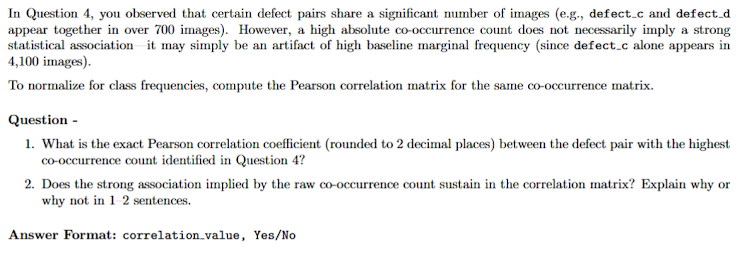

In [7]:
import pandas as pd
import numpy as np

CSV_PATH = "/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv"

df = pd.read_csv(CSV_PATH)

classes = ["defect_a", "defect_b", "defect_c", "defect_d"]

# Identify rows with a non-empty ground-truth mask
has_mask = (
    df["mask_rle"].notna()
    & df["mask_rle"].astype("string").str.strip().ne("")
)

# Build image-level binary presence matrix
presence = (
    df.assign(present=has_mask)
      .pivot(index="image_id", columns="defect_type", values="present")
      .reindex(columns=classes)
      .fillna(False)
      .astype(int)
)

# Pearson correlation matrix
corr = presence.corr(method="pearson")

print("Pearson correlation matrix:")
print(corr.round(4))

# Pair with the highest co-occurrence from Question 4
correlation = corr.loc["defect_c", "defect_d"]

# Raw co-occurrence count
cooccurrence = int(
    ((presence["defect_c"] == 1) & (presence["defect_d"] == 1)).sum()
)

print("\nCo-occurrence count:", cooccurrence)
print(f"Pearson correlation: {correlation:.2f}")

# Assess whether the raw association remains strong after normalization
print("Answer:", f"{correlation:.2f},", "Yes" if correlation >= 0.5 else "No")

Pearson correlation matrix:
defect_type  defect_a  defect_b  defect_c  defect_d
defect_type                                        
defect_a       1.0000    0.0225   -0.0493    0.0605
defect_b       0.0225    1.0000   -0.0197    0.0257
defect_c      -0.0493   -0.0197    1.0000    0.0465
defect_d       0.0605    0.0257    0.0465    1.0000

Co-occurrence count: 705
Pearson correlation: 0.05
Answer: 0.05, No


# Question 6: Pixel-Level Spatial Overlap and Mutual Exclusivity

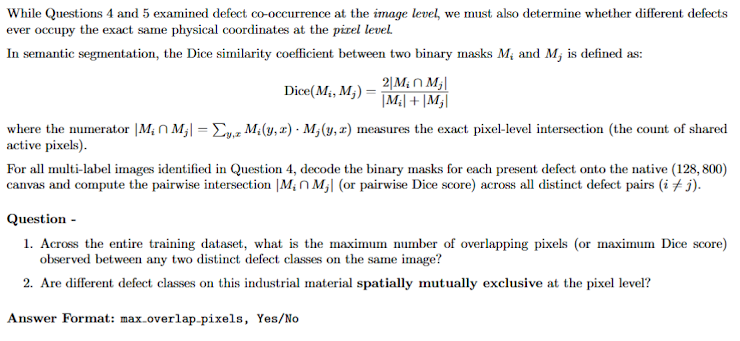

In [8]:
import pandas as pd
import numpy as np
from pathlib import Path

HEIGHT, WIDTH = 128, 800
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]

CSV_PATH = Path(
    "/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv"
)
df = pd.read_csv(CSV_PATH)


def decode_rle(rle):
    flat = np.zeros(HEIGHT * WIDTH, dtype=np.uint8)

    if pd.isna(rle) or not str(rle).strip():
        return flat.reshape((HEIGHT, WIDTH), order="F")

    values = np.fromstring(str(rle), sep=" ", dtype=np.int64)

    if len(values) % 2:
        raise ValueError("Malformed RLE")

    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        end = start + length
        if start < 0 or length <= 0 or end > HEIGHT * WIDTH:
            raise ValueError("RLE index out of bounds")
        flat[start:end] = 1

    return flat.reshape((HEIGHT, WIDTH), order="F")


# Convert annotations into one row per image and class
rle_table = df.pivot(
    index="image_id",
    columns="defect_type",
    values="mask_rle"
).reindex(columns=CLASSES)

max_overlap = 0
max_dice = 0.0
overlap_found = False
best_result = None

for image_id, row in rle_table.iterrows():
    masks = {
        cls: decode_rle(row[cls]).astype(bool)
        for cls in CLASSES
    }

    for i in range(len(CLASSES)):
        for j in range(i + 1, len(CLASSES)):
            a, b = CLASSES[i], CLASSES[j]
            mask_a, mask_b = masks[a], masks[b]

            intersection = int(np.logical_and(mask_a, mask_b).sum())

            if intersection > 0:
                overlap_found = True

            if intersection > max_overlap:
                max_overlap = intersection
                denom = int(mask_a.sum()) + int(mask_b.sum())
                max_dice = 2 * intersection / denom if denom else 1.0
                best_result = (image_id, a, b, intersection, max_dice)

print("Maximum overlapping pixels:", max_overlap)
print("Maximum Dice score:", round(max_dice, 6))
print("Image and defect pair:", best_result)
print("Mutually exclusive at pixel level:", not overlap_found)
print(f"\nAnswer: {max_overlap}, {'No' if overlap_found else 'Yes'}")

Maximum overlapping pixels: 0
Maximum Dice score: 0.0
Image and defect pair: None
Mutually exclusive at pixel level: True

Answer: 0, Yes


# Context for Questions 7 and 8

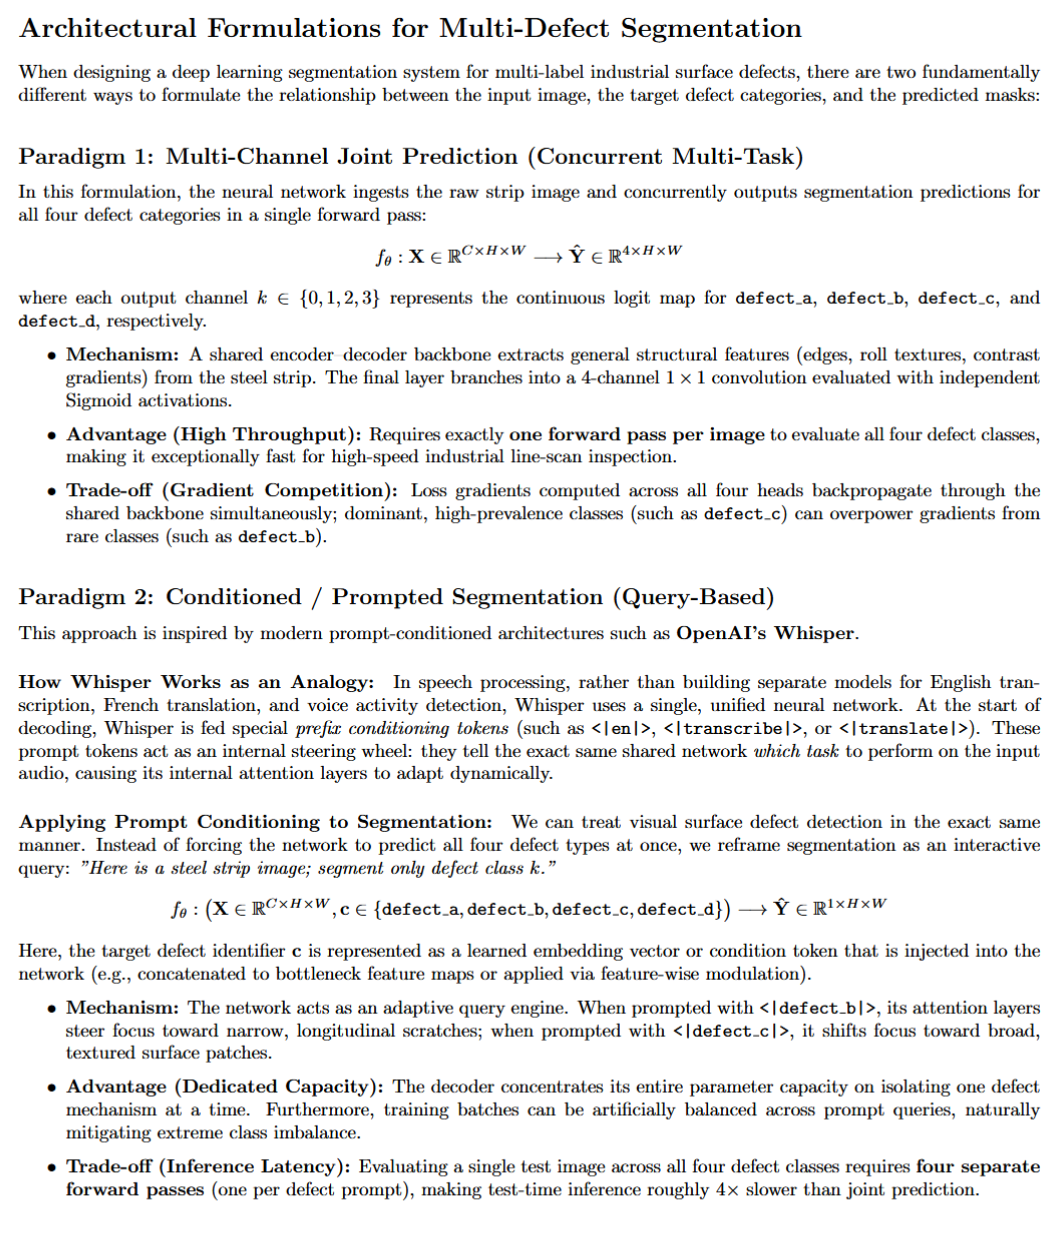

# Question 7: PyTorch Dataset for Paradigm 1

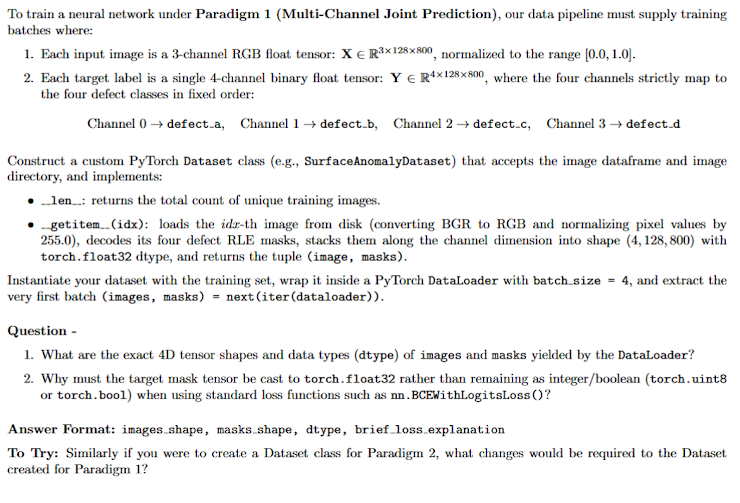

In [9]:
import pandas as pd
import numpy as np
import cv2
import torch

from pathlib import Path
from torch.utils.data import Dataset, DataLoader

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
DATA_ROOT = Path(
    "/kaggle/input/competitions/industrial-surface-defect-detection/public"
)
CSV_PATH = DATA_ROOT / "train.csv"
IMAGE_DIR = DATA_ROOT / "train"

HEIGHT, WIDTH = 128, 800
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
BATCH_SIZE = 4

df = pd.read_csv(CSV_PATH)

# --------------------------------------------------
# 2. Decode RLE into a binary mask
# --------------------------------------------------
def decode_rle(rle, height=HEIGHT, width=WIDTH):
    flat = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(rle) or not str(rle).strip():
        return flat.reshape((height, width), order="F")

    values = np.asarray(str(rle).split(), dtype=np.int64)

    if len(values) % 2:
        raise ValueError(f"Malformed RLE: {rle}")

    starts = values[0::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        end = start + length
        if start < 0 or length <= 0 or end > height * width:
            raise ValueError(f"Invalid RLE: {rle}")
        flat[start:end] = 1

    return flat.reshape((height, width), order="F")


# --------------------------------------------------
# 3. Build one row per image with four RLE columns
# --------------------------------------------------
df["mask_rle"] = df["mask_rle"].fillna("")

rle_table = df.pivot(
    index="image_id",
    columns="defect_type",
    values="mask_rle"
).reindex(columns=CLASSES, fill_value="")

rle_table = rle_table.fillna("")
image_ids = rle_table.index.tolist()


# --------------------------------------------------
# 4. Custom PyTorch Dataset
# --------------------------------------------------
class SurfaceAnomalyDataset(Dataset):
    def __init__(self, rle_table, image_dir):
        self.rle_table = rle_table
        self.image_dir = Path(image_dir)
        self.image_ids = rle_table.index.tolist()

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]

        filename = str(image_id)
        if not filename.lower().endswith(".jpg"):
            filename += ".jpg"

        image_path = self.image_dir / filename

        # OpenCV loads BGR; convert to RGB
        image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        if image is None:
            raise FileNotFoundError(f"Cannot read image: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if image.shape[:2] != (HEIGHT, WIDTH):
            raise ValueError(
                f"Unexpected dimensions for {image_id}: {image.shape}"
            )

        # RGB float32 normalized to [0, 1], channels-first
        image = image.astype(np.float32) / 255.0
        image = np.transpose(image, (2, 0, 1)).copy()

        # Decode four binary masks in the fixed class order
        row = self.rle_table.loc[image_id]
        masks = np.stack([
            decode_rle(row[cls]) for cls in CLASSES
        ], axis=0).astype(np.float32)

        return torch.from_numpy(image), torch.from_numpy(masks)


# --------------------------------------------------
# 5. Create dataset and DataLoader
# --------------------------------------------------
dataset = SurfaceAnomalyDataset(rle_table, IMAGE_DIR)

dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

images, masks = next(iter(dataloader))


# --------------------------------------------------
# 6. Print the requested results
# --------------------------------------------------
print("Unique training images:", len(dataset))
print("Images shape:", images.shape)
print("Masks shape:", masks.shape)
print("Images dtype:", images.dtype)
print("Masks dtype:", masks.dtype)

assert images.shape == (4, 3, 128, 800)
assert masks.shape == (4, 4, 128, 800)
assert images.dtype == torch.float32
assert masks.dtype == torch.float32

print(
    f"\nAnswer: {tuple(images.shape)}, {tuple(masks.shape)}, "
    f"{images.dtype}, BCEWithLogitsLoss requires floating-point "
    "targets in [0, 1] so it can compute differentiable "
    "pixel-wise binary cross-entropy against model logits."
)

Unique training images: 11393
Images shape: torch.Size([4, 3, 128, 800])
Masks shape: torch.Size([4, 4, 128, 800])
Images dtype: torch.float32
Masks dtype: torch.float32

Answer: (4, 3, 128, 800), (4, 4, 128, 800), torch.float32, BCEWithLogitsLoss requires floating-point targets in [0, 1] so it can compute differentiable pixel-wise binary cross-entropy against model logits.


# Question 8: Baseline Model Training Dynamics and Convergence

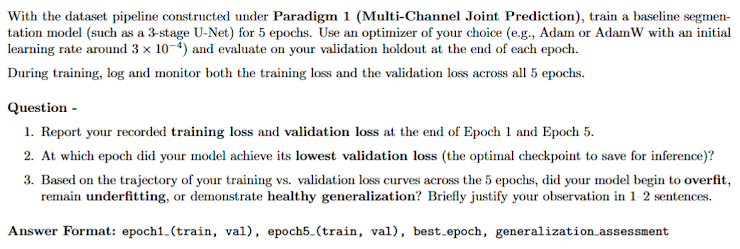

Device: cuda
CSV: /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
Images: /kaggle/input/competitions/industrial-surface-defect-detection/public/train
Unique images: 11393
Training images: 9114
Validation images: 2279
Batch image shape: (4, 3, 128, 800)
Batch mask shape: (4, 4, 128, 800)
Image dtype: torch.float32
Mask dtype: torch.float32
Epoch 1/5 | train_loss=0.052737 | val_loss=0.038856
Epoch 2/5 | train_loss=0.036980 | val_loss=0.034211
Epoch 3/5 | train_loss=0.033298 | val_loss=0.031264
Epoch 4/5 | train_loss=0.030018 | val_loss=0.027899
Epoch 5/5 | train_loss=0.028072 | val_loss=0.026359

Loss history:
 epoch  train_loss  val_loss
     1    0.052737  0.038856
     2    0.036980  0.034211
     3    0.033298  0.031264
     4    0.030018  0.027899
     5    0.028072  0.026359


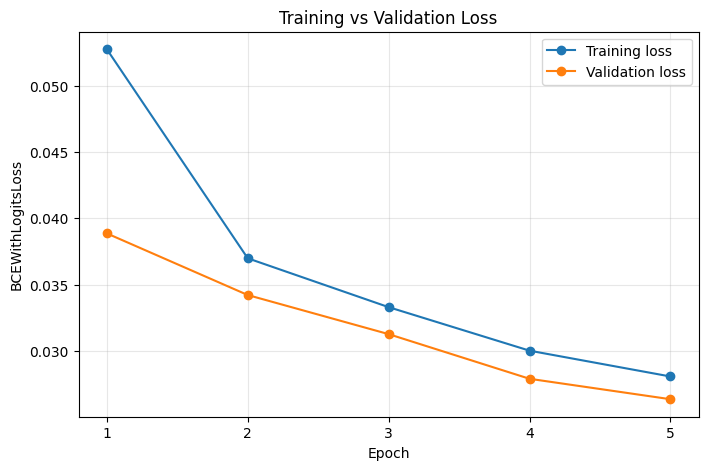


ANSWER FORMAT:
epoch1=(0.052737, 0.038856), epoch5=(0.028072, 0.026359), best_epoch=5, generalization_assessment=improving generalization
Best checkpoint: /kaggle/working/best_surface_unet.pth


In [10]:

import copy
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader


# 1. Configuration and paths
SEED = 42
EPOCHS = 5
BATCH_SIZE = 4
LEARNING_RATE = 3e-4

HEIGHT, WIDTH = 128, 800
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]

DATA_ROOT = Path(
    "/kaggle/input/competitions/industrial-surface-defect-detection/public"
)
CSV_PATH = DATA_ROOT / "train.csv"
TRAIN_DIR = DATA_ROOT / "train"
CHECKPOINT_PATH = Path("/kaggle/working/best_surface_unet.pth")

assert CSV_PATH.is_file(), f"Missing CSV: {CSV_PATH}"
assert TRAIN_DIR.is_dir(), f"Missing image directory: {TRAIN_DIR}"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("CSV:", CSV_PATH)
print("Images:", TRAIN_DIR)


# 2. Load annotations and validate
df = pd.read_csv(CSV_PATH)

required_columns = {"image_id", "defect_type", "mask_rle"}
assert required_columns.issubset(df.columns), (
    f"Missing columns: {required_columns - set(df.columns)}"
)

assert set(df["defect_type"].unique()).issubset(set(CLASSES))

# Normalize empty annotations
df["mask_rle"] = df["mask_rle"].fillna("").astype(str)

# One row per image, with one RLE column per defect class
rle_table = df.pivot(
    index="image_id",
    columns="defect_type",
    values="mask_rle"
).reindex(columns=CLASSES)

rle_table = rle_table.fillna("")
all_ids = rle_table.index.to_numpy()

# Reproducible image-level 80/20 split
rng = np.random.default_rng(SEED)
shuffled_ids = all_ids.copy()
rng.shuffle(shuffled_ids)

split_idx = int(0.8 * len(shuffled_ids))
train_ids = shuffled_ids[:split_idx].tolist()
val_ids = shuffled_ids[split_idx:].tolist()

print("Unique images:", len(all_ids))
print("Training images:", len(train_ids))
print("Validation images:", len(val_ids))


# 3. RLE decoder: 1-based, column-major
def decode_rle(rle):
    flat = np.zeros(HEIGHT * WIDTH, dtype=np.uint8)

    if not str(rle).strip():
        return flat.reshape((HEIGHT, WIDTH), order="F")

    values = np.fromstring(str(rle), sep=" ", dtype=np.int64)

    if len(values) % 2 != 0:
        raise ValueError(f"Malformed RLE: {rle}")

    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths

    if (
        np.any(starts < 0)
        or np.any(lengths <= 0)
        or np.any(ends > HEIGHT * WIDTH)
    ):
        raise ValueError("RLE contains an out-of-bounds run")

    for start, end in zip(starts, ends):
        flat[start:end] = 1

    return flat.reshape((HEIGHT, WIDTH), order="F")


# 4. Dataset: RGB image + four binary masks
class SurfaceAnomalyDataset(Dataset):
    def __init__(self, image_ids, annotations, image_dir):
        self.image_ids = list(image_ids)
        self.annotations = annotations
        self.image_dir = Path(image_dir)

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        filename = str(image_id)

        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            filename += ".jpg"

        image_path = self.image_dir / filename
        image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)

        if image is None:
            raise FileNotFoundError(f"Could not read {image_path}")

        # OpenCV BGR -> RGB
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if image.shape[:2] != (HEIGHT, WIDTH):
            raise ValueError(
                f"Unexpected image shape for {image_id}: {image.shape}"
            )

        # Float32 RGB in [0, 1], shape (3, H, W)
        image = image.astype(np.float32) / 255.0
        image = np.transpose(image, (2, 0, 1)).copy()

        row = self.annotations.loc[image_id]
        masks = np.stack(
            [decode_rle(row[cls]) for cls in CLASSES],
            axis=0
        ).astype(np.float32)

        return torch.from_numpy(image), torch.from_numpy(masks)

train_dataset = SurfaceAnomalyDataset(train_ids, rle_table, TRAIN_DIR)
val_dataset = SurfaceAnomalyDataset(val_ids, rle_table, TRAIN_DIR)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

# Verify first batch
images, masks = next(iter(train_loader))
print("Batch image shape:", tuple(images.shape))
print("Batch mask shape:", tuple(masks.shape))
print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)

assert images.shape[1:] == (3, HEIGHT, WIDTH)
assert masks.shape[1:] == (4, HEIGHT, WIDTH)
assert images.dtype == torch.float32
assert masks.dtype == torch.float32


# 5. Three-stage U-Net
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class SurfaceUNet(nn.Module):
    def __init__(self, base=16):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = ConvBlock(3, base)
        self.enc2 = ConvBlock(base, base * 2)
        self.enc3 = ConvBlock(base * 2, base * 4)
        self.bottleneck = ConvBlock(base * 4, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, 2)
        self.dec3 = ConvBlock(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, 2)
        self.dec2 = ConvBlock(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, 2)
        self.dec1 = ConvBlock(base * 2, base)

        # Four independent defect logits
        self.output = nn.Conv2d(base, 4, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bottleneck(self.pool(e3))

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.output(d1)

model = SurfaceUNet(base=16).to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE
)

# 6. Train for five epochs and validate every epoch
history = []
best_val_loss = float("inf")
best_epoch = None
best_state = None

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0
    train_count = 0

    for images, masks in train_loader:
        images = images.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE, dtype=torch.float32)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        n = images.size(0)
        train_loss_sum += loss.item() * n
        train_count += n

    train_loss = train_loss_sum / train_count

    model.eval()
    val_loss_sum = 0.0
    val_count = 0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(DEVICE, dtype=torch.float32)
            masks = masks.to(DEVICE, dtype=torch.float32)

            logits = model(images)
            loss = criterion(logits, masks)

            n = images.size(0)
            val_loss_sum += loss.item() * n
            val_count += n

    val_loss = val_loss_sum / val_count

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train_loss={train_loss:.6f} | "
        f"val_loss={val_loss:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())

        torch.save({
            "epoch": epoch,
            "model_state_dict": best_state,
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss,
            "classes": CLASSES
        }, CHECKPOINT_PATH)


# 7. Loss history, plot, and requested answer
history_df = pd.DataFrame(history)
print("\nLoss history:")
print(history_df.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o",
         label="Training loss")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o",
         label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("BCEWithLogitsLoss")
plt.title("Training vs Validation Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

e1 = history_df.iloc[0]
e5 = history_df.iloc[-1]

train_losses = history_df["train_loss"].to_numpy()
val_losses = history_df["val_loss"].to_numpy()

if (
    train_losses[-1] < train_losses[0]
    and val_losses[-1] > val_losses[0]
):
    assessment = "possible overfitting"
elif train_losses[-1] > train_losses[0] and val_losses[-1] > val_losses[0]:
    assessment = "inconclusive or underfitting"
elif val_losses[-1] < val_losses[0] and train_losses[-1] < train_losses[0]:
    assessment = "improving generalization"
else:
    assessment = "inconclusive; inspect the loss curves"

print("\nANSWER FORMAT:")
print(
    f"epoch1=({e1['train_loss']:.6f}, {e1['val_loss']:.6f}), "
    f"epoch5=({e5['train_loss']:.6f}, {e5['val_loss']:.6f}), "
    f"best_epoch={best_epoch}, "
    f"generalization_assessment={assessment}"
)

print("Best checkpoint:", CHECKPOINT_PATH)
